# Análisis de las tablas Gold — Transfermarkt

Consultas y gráficos para verificar el resultado del pipeline `tp_transfermarkt_medallion`. Cada sección responde una pregunta de negocio usando una tabla Gold.

In [0]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

S = "workspace.tp_transfermarkt"
spark.sql(f"USE {S}")

DataFrame[]

## 0. Reconciliación entre capas

Cantidad de filas de cada tabla en Bronze y Silver, para verificar que no se perdieron datos fuera de los controles de calidad.

In [0]:
tablas = ["competitions", "clubs", "players", "games",
          "appearances", "player_valuations", "transfers"]
filas = [(t, spark.table(f"bronze_{t}").count(), spark.table(f"silver_{t}").count()) for t in tablas]
reconciliacion = (spark.createDataFrame(filas, ["tabla", "bronze", "silver"])
                  .withColumn("diferencia", F.col("bronze") - F.col("silver")))
display(reconciliacion)

tabla,bronze,silver,diferencia
competitions,65,65,0
clubs,796,796,0
players,50149,50149,0
games,88958,88958,0
appearances,1894350,1894350,0
player_valuations,656301,656300,1
transfers,175165,175165,0


## 1. ¿Quiénes son los jugadores más valiosos hoy?

Fuente: `gold_player_market_value`.

name,position,current_club_name,edad_en_ultima_valuacion,valor_actual_millones,valor_maximo_millones
Erling Haaland,Attack,Manchester City,25,200.0,200.0
Lamine Yamal,Attack,FC Barcelona,18,200.0,200.0
Kylian Mbappé,Attack,Real Madrid,27,180.0,200.0
Michael Olise,Attack,Bayern Munich,24,150.0,150.0
Pedri,Midfield,FC Barcelona,23,150.0,150.0
Vinicius Junior,Attack,Real Madrid,25,140.0,200.0
Vitinha,Midfield,Paris Saint-Germain,26,140.0,140.0
João Neves,Midfield,Paris Saint-Germain,21,140.0,140.0
Khvicha Kvaratskhelia,Attack,Paris Saint-Germain,25,140.0,140.0
Jude Bellingham,Midfield,Real Madrid,22,130.0,180.0


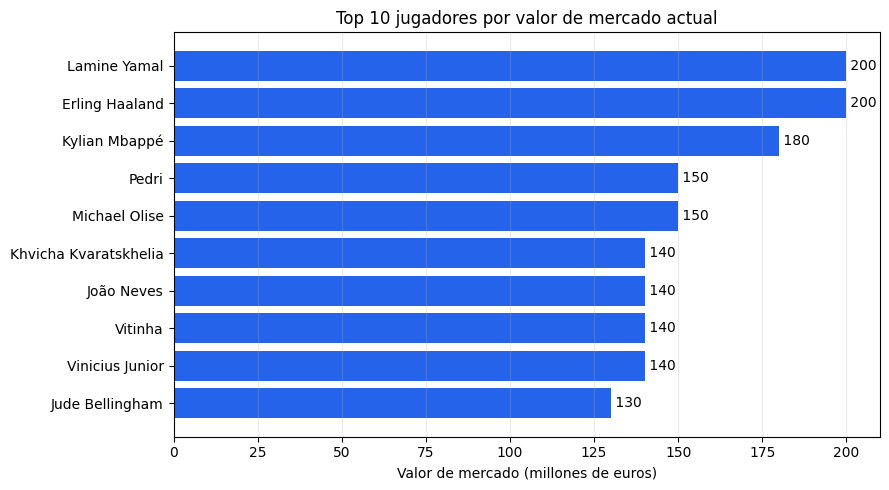

In [0]:
top_valor = (spark.table("gold_player_market_value")
             .orderBy(F.desc("valor_actual_eur"))
             .limit(10)
             .select("name", "position", "current_club_name", "edad_en_ultima_valuacion",
                     (F.col("valor_actual_eur") / 1e6).alias("valor_actual_millones"),
                     (F.col("valor_maximo_eur") / 1e6).alias("valor_maximo_millones")))
display(top_valor)

pdf = top_valor.toPandas().sort_values("valor_actual_millones")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(pdf["name"], pdf["valor_actual_millones"], color="#2563eb")
for y, v in zip(pdf["name"], pdf["valor_actual_millones"]):
    ax.text(v, y, f" {v:.0f}", va="center")
ax.set_title("Top 10 jugadores por valor de mercado actual")
ax.set_xlabel("Valor de mercado (millones de euros)")
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

## 2. ¿Cómo evolucionó el valor del jugador más caro?

Fuente: `silver_player_valuations` (historia completa) filtrada por el jugador líder de la sección anterior.

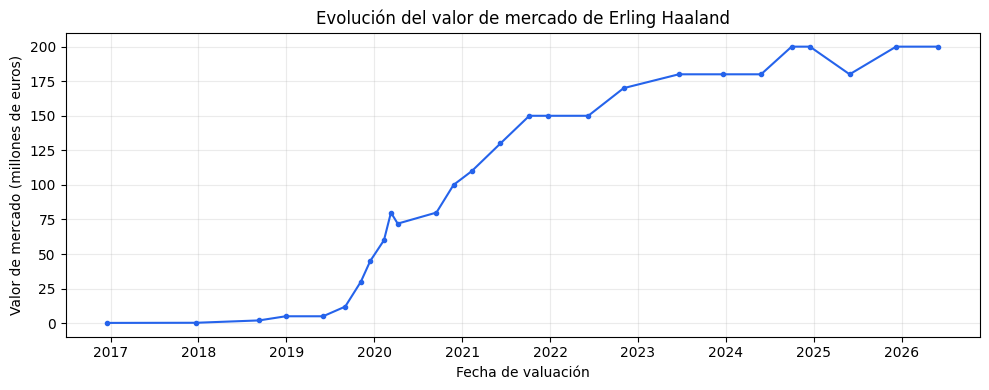

In [0]:
lider = spark.table("gold_player_market_value").orderBy(F.desc("valor_actual_eur")).first()
historia = (spark.table("silver_player_valuations")
            .where(F.col("player_id") == lider.player_id)
            .orderBy("date")
            .select("date", (F.col("market_value_in_eur") / 1e6).alias("valor_millones")))

pdf = historia.toPandas()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(pdf["date"], pdf["valor_millones"], marker="o", markersize=3, color="#2563eb")
ax.set_title(f"Evolución del valor de mercado de {lider.name}")
ax.set_ylabel("Valor de mercado (millones de euros)")
ax.set_xlabel("Fecha de valuación")
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## 3. ¿Qué clubes gastaron más en transferencias y cuál es su balance?

Fuente: `gold_club_transfer_balance`, sumando todas las temporadas.

club_id,club_name,gasto_millones,ingreso_millones,balance_millones
631,Chelsea,3005.15,1384.48,-1620.67
281,Man City,2478.43,981.3,-1497.13
985,Man Utd,2383.15,758.52,-1624.63
583,Paris SG,2041.52,698.1,-1343.42
31,Liverpool,1853.955,882.6,-971.355
11,Arsenal,1750.58,438.43,-1312.15
131,Barcelona,1695.81,1067.1,-628.71
506,Juventus,1678.9,1111.87,-567.03
148,Tottenham,1616.88,601.65,-1015.23
418,Real Madrid,1517.15,832.95,-684.2


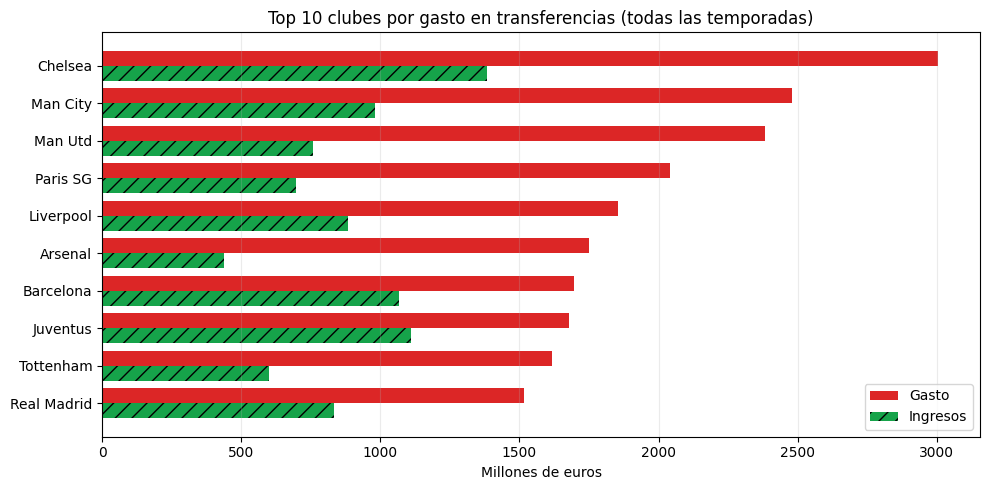

In [0]:
clubes = (spark.table("gold_club_transfer_balance")
          .groupBy("club_id")
          .agg(F.first("club_name", ignorenulls=True).alias("club_name"),
               (F.sum("gasto_eur") / 1e6).alias("gasto_millones"),
               (F.sum("ingreso_eur") / 1e6).alias("ingreso_millones"),
               (F.sum("balance_eur") / 1e6).alias("balance_millones"))
          .orderBy(F.desc("gasto_millones"))
          .limit(10))
display(clubes)

pdf = clubes.toPandas().sort_values("gasto_millones")
fig, ax = plt.subplots(figsize=(10, 5))
y = range(len(pdf))
ax.barh([i + 0.2 for i in y], pdf["gasto_millones"], height=0.4, color="#dc2626", label="Gasto")
ax.barh([i - 0.2 for i in y], pdf["ingreso_millones"], height=0.4, color="#16a34a", hatch="//", label="Ingresos")
ax.set_yticks(list(y))
ax.set_yticklabels(pdf["club_name"])
ax.set_title("Top 10 clubes por gasto en transferencias (todas las temporadas)")
ax.set_xlabel("Millones de euros")
ax.legend()
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

## 4. ¿Cómo cambiaron los goles y la ventaja de local en las 5 grandes ligas?

Fuente: `gold_competition_season`. Ligas: Premier League (GB1), LaLiga (ES1), Serie A (IT1), Bundesliga (L1) y Ligue 1 (FR1).

competition_id,competition_name,country_name,season,partidos,goles_promedio,pct_gana_local,pct_empate,pct_gana_visitante,asistencia_promedio
ES1,laliga,Spain,2012,380,2.87,49.7,22.1,28.2,28563.0
ES1,laliga,Spain,2013,380,2.75,47.1,22.6,30.3,26991.0
ES1,laliga,Spain,2014,380,2.66,45.0,23.9,31.1,26791.0
ES1,laliga,Spain,2015,380,2.74,48.2,24.2,27.6,27974.0
ES1,laliga,Spain,2016,380,2.94,47.6,23.4,28.9,28183.0
ES1,laliga,Spain,2017,380,2.69,47.1,22.6,30.3,27290.0
ES1,laliga,Spain,2018,380,2.59,44.2,28.9,26.8,27092.0
ES1,laliga,Spain,2019,380,2.48,45.8,27.6,26.6,29233.0
ES1,laliga,Spain,2020,380,2.51,41.6,28.7,29.7,3529.0
ES1,laliga,Spain,2021,380,2.5,43.4,29.2,27.4,22972.0


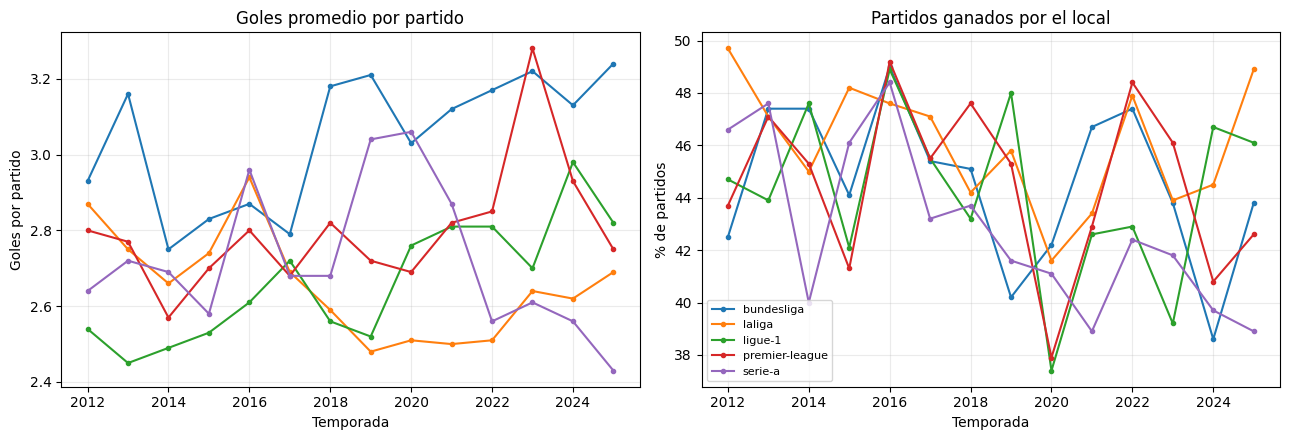

In [0]:
ligas = ["GB1", "ES1", "IT1", "L1", "FR1"]
resumen = (spark.table("gold_competition_season")
           .where(F.col("competition_id").isin(ligas))
           .orderBy("competition_id", "season"))
display(resumen)

pdf = resumen.toPandas()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for liga, d in pdf.groupby("competition_name"):
    ax1.plot(d["season"], d["goles_promedio"], marker="o", markersize=3, label=liga)
    ax2.plot(d["season"], d["pct_gana_local"], marker="o", markersize=3, label=liga)
ax1.set_title("Goles promedio por partido")
ax1.set_xlabel("Temporada")
ax1.set_ylabel("Goles por partido")
ax2.set_title("Partidos ganados por el local")
ax2.set_xlabel("Temporada")
ax2.set_ylabel("% de partidos")
for ax in (ax1, ax2):
    ax.grid(alpha=0.25)
ax2.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. ¿Quiénes fueron los goleadores de la última temporada completa?

Fuente: `gold_player_season_stats`. Se toma la última temporada con al menos 1.000 partidos registrados para evitar una temporada en curso.

In [0]:
temporadas = (spark.table("silver_games").groupBy("season").count()
              .where("count >= 1000").agg(F.max("season")).first()[0])
goleadores = (spark.table("gold_player_season_stats")
              .where(F.col("season") == temporadas)
              .orderBy(F.desc("goles"), F.desc("asistencias"))
              .limit(15))
print("Temporada:", temporadas)
display(goleadores)

Temporada: 2025


player_id,season,player_name,partidos,minutos,goles,asistencias,amarillas,rojas,goles_por_90
132098,2025,Harry Kane,58,4600,64,8,4,0,1.252
342229,2025,Kylian Mbappé,50,4023,47,9,6,0,1.051
418560,2025,Erling Haaland,57,4491,45,10,2,0,0.902
424784,2025,Luis Suárez,49,3935,34,9,10,0,0.778
339314,2025,Deniz Undav,48,3641,28,16,8,0,0.692
552655,2025,Troy Parrott,38,2995,28,11,7,0,0.841
324503,2025,Vangelis Pavlidis,54,4333,28,7,5,0,0.582
589128,2025,Ayase Ueda,43,3460,28,3,2,0,0.728
480692,2025,Luis Díaz,53,4240,27,23,8,0,0.573
371998,2025,Vinicius Junior,62,4964,27,16,12,0,0.49
